# Exoplanet Explorer: Wrangling the Open Exoplanet Catalogue
**Course:** Data Wrangling and Preprocessing (DWP) - Mini Project

We collect a catalogue of planets outside our Solar System, integrate it with a star catalogue,
clean and transform it, explore it, and prepare it for modelling.
The cleaned output feeds an interactive **Streamlit dashboard** (`app.py`).

**Questions:** How did exoplanet discovery grow? What kinds of planets exist? Which are in the
habitable zone of their star? Can we predict a planet's size from its orbit and star?

In [1]:
import io
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
RAW, PROC, FIG = BASE / "data" / "raw", BASE / "data" / "processed", BASE / "outputs" / "figures"
for d in (RAW, PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)

REPORT, WLOG = [], {}  # REPORT -> outputs/report.md, WLOG -> dashboard "Data Quality" tab


def log(msg=""):
    print(msg)
    REPORT.append(msg)


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=130)
    plt.show()
    plt.close()


# Physical constants used for unit conversion / derived features
MJUP_TO_MEARTH = 317.83
RJUP_TO_REARTH = 11.209
PC_TO_LY = 3.26156
RSUN_AU = 0.00465047
TSUN = 5772.0

## 1. Data Collection
| Key | Source | Content |
|---|---|---|
| `oec` | Open Exoplanet Catalogue (GitHub) | ~5,400 planets: orbit, mass, radius, host star, discovery method/year |
| `hyg` | HYG Star Database (GitHub) | ~120,000 stars: spectral type, colour, luminosity, constellation, distance |

Files are cached in `data/raw/`. The star file is 34 MB, so only the columns we need are kept.

In [2]:
OEC_URL = ("https://raw.githubusercontent.com/OpenExoplanetCatalogue/oec_tables/master/"
           "comma_separated/open_exoplanet_catalogue.txt")
HYG_URL = "https://raw.githubusercontent.com/astronexus/HYG-Database/main/hyg/CURRENT/hygdata_v41.csv"
HYG_COLS = ["hip", "hd", "gl", "proper", "dist", "mag", "absmag", "spect", "ci", "lum", "con"]


def download(url):
    r = requests.get(url, timeout=180)
    r.raise_for_status()
    return r.content


oec_path, hyg_path = RAW / "oec.csv", RAW / "hyg_slim.csv"
if not oec_path.exists():
    print("Downloading Open Exoplanet Catalogue ...")
    oec_path.write_bytes(download(OEC_URL))
if not hyg_path.exists():
    print("Downloading HYG star database (34 MB, one time) ...")
    pd.read_csv(io.BytesIO(download(HYG_URL)), usecols=HYG_COLS, low_memory=False).to_csv(hyg_path, index=False)

oec_raw, hyg_raw = pd.read_csv(oec_path), pd.read_csv(hyg_path, low_memory=False)
log(f"- Open Exoplanet Catalogue: {oec_raw.shape[0]:,} rows x {oec_raw.shape[1]} columns")
log(f"- HYG star database (selected columns): {hyg_raw.shape[0]:,} rows x {hyg_raw.shape[1]} columns")
WLOG["raw_rows"], WLOG["raw_cols"] = int(oec_raw.shape[0]), int(oec_raw.shape[1])
WLOG["missing_before"] = (oec_raw.isna().mean() * 100).round(1).to_dict()

- Open Exoplanet Catalogue: 5,414 rows x 25 columns
- HYG star database (selected columns): 119,626 rows x 11 columns


## 2. Data Audit

In [3]:
audit = pd.DataFrame({"dtype": oec_raw.dtypes.astype(str),
                      "missing_%": (oec_raw.isna().mean() * 100).round(1),
                      "n_unique": oec_raw.nunique()}).sort_values("missing_%", ascending=False)
print(audit.head(14))

                        dtype  missing_%  n_unique
age                   float64       99.9         4
longitude             float64       99.2        43
ascendingnode         float64       99.0        43
hoststar_age          float64       89.0       215
periastron            float64       81.3       736
temperature           float64       69.8      1299
inclination           float64       68.3       767
eccentricity          float64       59.8       492
mass                  float64       48.7      1737
semimajoraxis         float64       48.0      1915
hoststar_metallicity  float64       29.3       344
radius                float64       23.1      1492
hoststar_radius       float64       11.7       923
hoststar_temperature  float64       10.7      1947


In [4]:
log("- Catalogue `list` column (status) values: " +
    "; ".join(f"{k.split(',')[0]}={v}" for k, v in
              oec_raw["list"].str.split(",").str[0].str.strip().value_counts().items()))
log(f"- Missing: age {oec_raw['age'].isna().mean():.0%}, mass {oec_raw['mass'].isna().mean():.0%}, "
    f"radius {oec_raw['radius'].isna().mean():.0%}, eccentricity {oec_raw['eccentricity'].isna().mean():.0%}")
log(f"- Duplicate planet names: {oec_raw['name'].duplicated().sum()}")
sentinel = (hyg_raw["dist"] >= 100000).sum()
log(f"- HYG hides 'unknown distance' as a sentinel value 100000 pc: {sentinel:,} stars affected "
    f"({sentinel / len(hyg_raw):.1%}). Left as-is, it would wreck any distance statistics.")

- Catalogue `list` column (status) values: Confirmed planets=5287; Controversial=100; Retracted planet candidate=12; Solar System=9; Kepler Objects of Interest=5; Planets in binary systems=1
- Missing: age 100%, mass 49%, radius 23%, eccentricity 60%
- Duplicate planet names: 0
- HYG hides 'unknown distance' as a sentinel value 100000 pc: 10,225 stars affected (8.5%). Left as-is, it would wreck any distance statistics.


## 3. Data Cleaning
Steps: remove non-confirmed objects -> separate Solar System reference -> fix types/dates ->
convert coordinates -> drop sparse columns -> physical-range checks -> flag outliers.

In [5]:
oec = oec_raw.copy()
oec["name"] = oec["name"].str.strip()

# 3.1 Status: the `list` column mixes status and environment tags ("Confirmed planets, Planets in binary systems, S-type")
first = oec["list"].str.split(",").str[0].str.strip()
oec["status"] = np.select(
    [first.eq("Confirmed planets") | oec["list"].str.contains("Confirmed planets", na=False),
     first.eq("Controversial"), first.eq("Retracted planet candidate"), first.eq("Solar System")],
    ["Confirmed", "Controversial", "Retracted", "Solar System"], default="Candidate (KOI)")
oec["in_binary_system"] = oec["list"].str.contains("binary", na=False)
log("- Status counts: " + ", ".join(f"{k}={v}" for k, v in oec["status"].value_counts().items()))

# 3.2 Keep the Solar System aside as a REFERENCE for plots (not exoplanets!)
solar = oec[oec["status"] == "Solar System"].copy()
oec = oec[oec["status"] == "Confirmed"].copy()
WLOG["rows_dropped_not_confirmed"] = int(len(oec_raw) - len(oec) - len(solar))
log(f"- Removed {WLOG['rows_dropped_not_confirmed']} non-confirmed objects (controversial, retracted, candidates) "
    f"and set aside {len(solar)} Solar System bodies as reference points.")

- Status counts: Confirmed=5288, Controversial=100, Retracted=12, Solar System=9, Candidate (KOI)=5
- Removed 117 non-confirmed objects (controversial, retracted, candidates) and set aside 9 Solar System bodies as reference points.


In [6]:
# 3.3 Types and dates: discovery year -> integer; lastupdate is a 2-digit-year string dd/mm/yy
n_no_year = oec["discoveryyear"].isna().sum()
oec = oec.dropna(subset=["discoveryyear"]).copy()
oec["discoveryyear"] = oec["discoveryyear"].astype(int)
oec["lastupdate"] = pd.to_datetime(oec["lastupdate"], format="%d/%m/%y", errors="coerce")
log(f"- Dropped {n_no_year} confirmed planets with no discovery year; parsed `lastupdate` to datetime "
    f"({oec['lastupdate'].isna().sum()} unparseable/missing).")


# 3.4 Coordinates are text ("19 19 43.40", "+40 05 51.84"): convert to decimal degrees
def sexagesimal(s, hours=False):
    if pd.isna(s):
        return np.nan
    parts = re.split(r"\s+", str(s).strip())
    sign = -1 if parts[0].startswith("-") else 1
    vals = [abs(float(p)) for p in parts[:3]] + [0.0] * (3 - len(parts[:3]))
    deg = vals[0] + vals[1] / 60 + vals[2] / 3600
    return sign * deg * (15 if hours else 1)


oec["ra_deg"] = oec["system_rightascension"].map(lambda s: sexagesimal(s, hours=True))
oec["dec_deg"] = oec["system_declination"].map(sexagesimal)
log(f"- Converted RA/Dec text to degrees. Missing coordinates: {oec['ra_deg'].isna().sum()}")

- Dropped 0 confirmed planets with no discovery year; parsed `lastupdate` to datetime (1 unparseable/missing).
- Converted RA/Dec text to degrees. Missing coordinates: 0


In [7]:
# 3.5 Drop columns that are too sparse to be useful (> 75% missing among confirmed planets)
miss = oec.isna().mean()
sparse = miss[miss > 0.75].index.tolist()
oec = oec.drop(columns=sparse + ["system_rightascension", "system_declination", "list", "binaryflag"])
log(f"- Dropped sparse columns (> 75% missing): {sparse}")

# 3.6 Rename to clear snake_case names with units in the name
oec = oec.rename(columns={"mass": "mass_mjup", "radius": "radius_rjup", "period": "period_days",
                          "semimajoraxis": "sma_au", "temperature": "temp_k", "system_distance": "distance_pc",
                          "discoverymethod": "method", "discoveryyear": "disc_year", "hoststar_mass": "star_mass_msun",
                          "hoststar_radius": "star_radius_rsun", "hoststar_metallicity": "star_metallicity",
                          "hoststar_temperature": "star_temp_k", "eccentricity": "eccentricity"})

- Dropped sparse columns (> 75% missing): ['periastron', 'longitude', 'ascendingnode', 'age', 'hoststar_age']


- Planets above the 13 Jupiter-mass deuterium-burning limit (may really be brown dwarfs): 74 (flagged, kept)
- Orbital-period outliers flagged (log-IQR): 281 (longest 22,012 years). They are real directly-imaged planets, so flagged not removed.


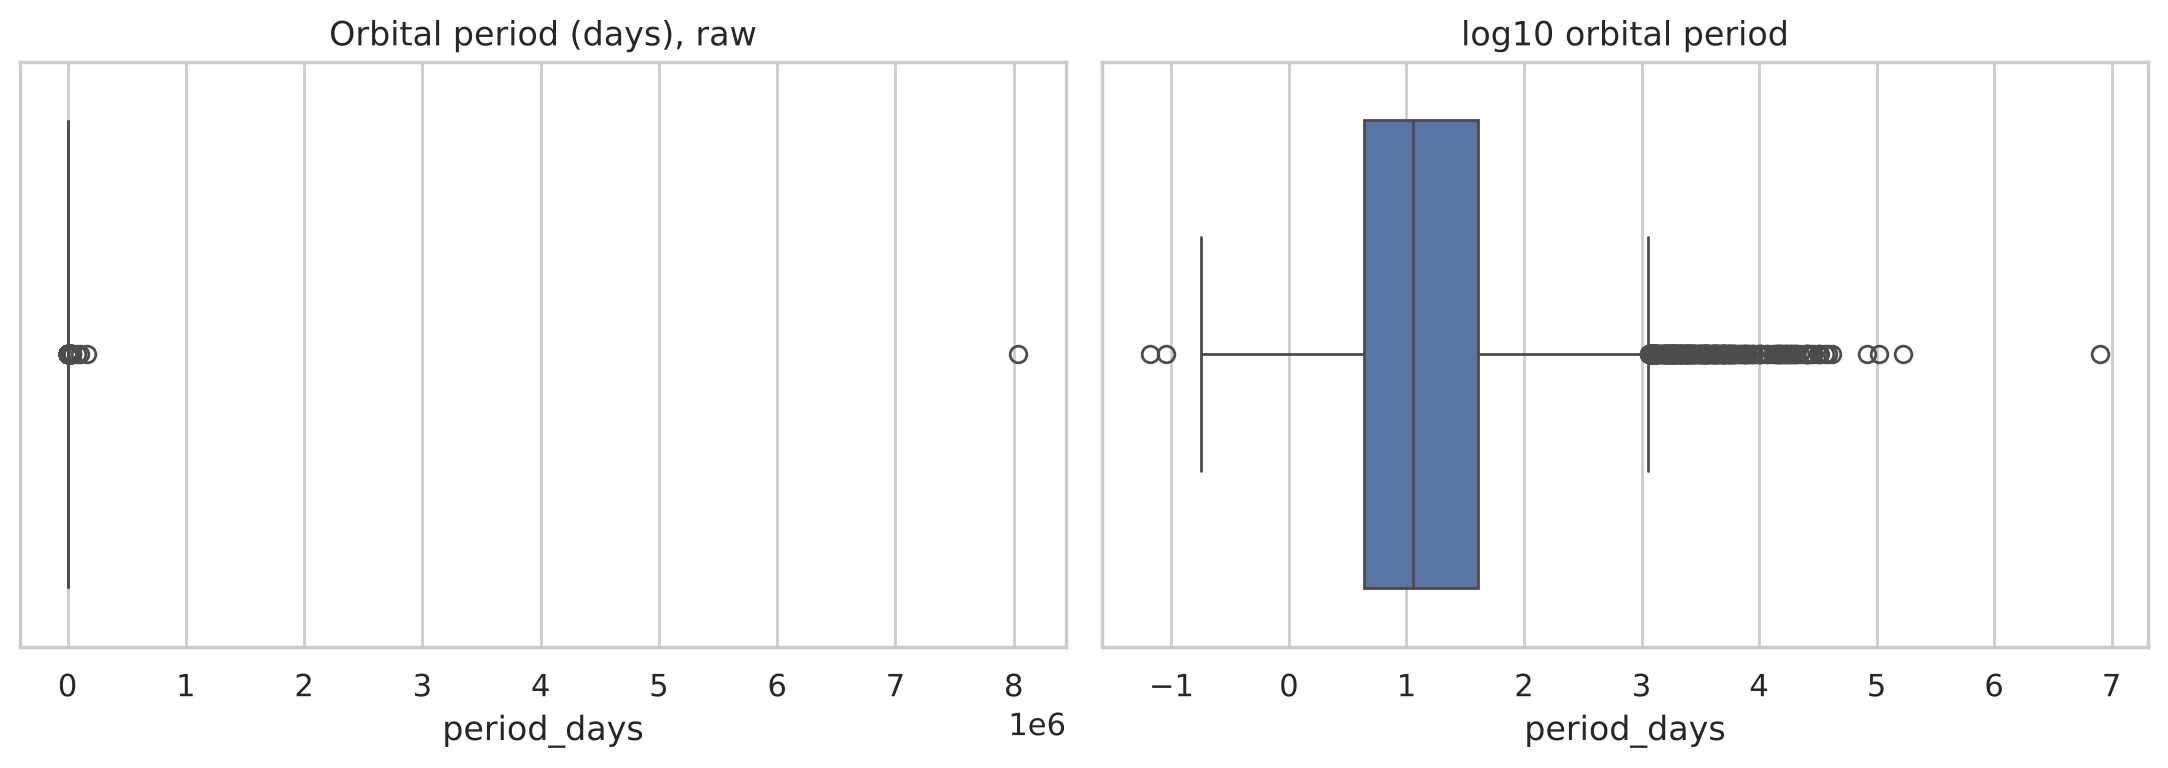

In [8]:
# 3.7 Physical validation: values must be positive; mass above ~13 Jupiter masses = brown-dwarf territory
for c in ["mass_mjup", "radius_rjup", "period_days", "sma_au", "distance_pc", "star_temp_k", "star_radius_rsun"]:
    bad = (oec[c] <= 0).sum()
    oec.loc[oec[c] <= 0, c] = np.nan
    if bad:
        log(f"- Non-positive {c} set to NaN: {bad}")
oec["above_deuterium_limit"] = oec["mass_mjup"] > 13
log(f"- Planets above the 13 Jupiter-mass deuterium-burning limit (may really be brown dwarfs): "
    f"{int(oec['above_deuterium_limit'].sum())} (flagged, kept)")
oec["eccentricity"] = oec["eccentricity"].where(oec["eccentricity"].between(0, 1))

# 3.8 Outliers: orbital period is extremely skewed, so use the IQR rule on log10
lp = np.log10(oec["period_days"])
q1, q3 = lp.quantile([0.25, 0.75])
iqr = q3 - q1
oec["period_outlier"] = ~lp.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr) & lp.notna()
log(f"- Orbital-period outliers flagged (log-IQR): {int(oec['period_outlier'].sum())} "
    f"(longest {oec['period_days'].max() / 365.25:,.0f} years). They are real directly-imaged planets, so flagged not removed.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=oec["period_days"], ax=ax[0]); ax[0].set_title("Orbital period (days), raw")
sns.boxplot(x=lp, ax=ax[1]); ax[1].set_title("log10 orbital period")
savefig("01_outliers.png")

## 4. Data Transformation
Unit conversion (Jupiter -> Earth units), derived physical features, binning, encoding.

In [9]:
oec["mass_earth"] = oec["mass_mjup"] * MJUP_TO_MEARTH
oec["radius_earth"] = oec["radius_rjup"] * RJUP_TO_REARTH
oec["distance_ly"] = oec["distance_pc"] * PC_TO_LY
oec["disc_decade"] = (oec["disc_year"] // 10) * 10

# Density relative to Earth (rho/rho_earth = M / R^3): rocky ~1, gas giants << 1
oec["density_earth"] = oec["mass_earth"] / oec["radius_earth"] ** 3

# Cleaner method names for charts
oec["method"] = oec["method"].replace({"RV": "Radial velocity", "transit": "Transit", "imaging": "Direct imaging",
                                       "microlensing": "Microlensing", "timing": "Timing",
                                       "astrometry": "Astrometry", "disk kinematics": "Disk kinematics"})

In [10]:
# 4.1 Binning: planet size class from radius; fall back to mass when radius is missing
r_bins, r_lab = [0, 1.25, 2, 6, np.inf], ["Earth-size", "Super-Earth", "Neptune-size", "Jupiter-size"]
m_bins = [0, 2, 17, 130, np.inf]  # Earth masses, rough Chen & Kipping style boundaries
oec["size_class"] = pd.cut(oec["radius_earth"], r_bins, labels=r_lab)
oec["size_class_source"] = np.where(oec["size_class"].notna(), "radius", None)
from_mass = oec["size_class"].isna() & oec["mass_earth"].notna()
oec["size_class"] = oec["size_class"].astype(object)
oec.loc[from_mass, "size_class"] = pd.cut(oec.loc[from_mass, "mass_earth"], m_bins, labels=r_lab).astype(object)
oec.loc[from_mass, "size_class_source"] = "mass (estimated)"
oec["size_class"] = pd.Categorical(oec["size_class"], r_lab, ordered=True)
log(f"- Size class assigned for {oec['size_class'].notna().mean():.0%} of planets "
    f"({from_mass.sum()} of them estimated from mass because radius was missing).")

# 4.2 Star class from temperature (Harvard sequence: O B A F G K M)
oec["star_class"] = pd.cut(oec["star_temp_k"], [0, 3700, 5200, 6000, 7500, 10000, 30000, np.inf],
                           labels=["M", "K", "G", "F", "A", "B", "O"])

- Size class assigned for 100% of planets (1152 of them estimated from mass because radius was missing).


In [11]:
# 4.3 Stellar luminosity (solar units) from radius and temperature: L = R^2 (T / T_sun)^4
oec["star_lum_lsun"] = oec["star_radius_rsun"] ** 2 * (oec["star_temp_k"] / TSUN) ** 4

# 4.4 Simple habitable-zone estimate: flux limits 1.1 (inner) and 0.53 (outer) times Earth's
#     -> boundaries in AU = sqrt(L / S). This is a simplification of the Kopparapu et al. model.
oec["hz_inner_au"] = np.sqrt(oec["star_lum_lsun"] / 1.1)
oec["hz_outer_au"] = np.sqrt(oec["star_lum_lsun"] / 0.53)
oec["in_hz"] = oec["sma_au"].between(oec["hz_inner_au"], oec["hz_outer_au"])
small = (oec["radius_earth"] <= 2) | (oec["radius_earth"].isna() & (oec["mass_earth"] <= 10))
oec["hz_candidate"] = oec["in_hz"] & small
log(f"- Planets in the (estimated) habitable zone: {int(oec['in_hz'].sum())}; "
    f"small/rocky ones (HZ candidates): {int(oec['hz_candidate'].sum())}")

# 4.5 Cross-check: our computed equilibrium temperature vs the catalogue's reported one
a_in_rsun = oec["sma_au"] / RSUN_AU
oec["teq_calc_k"] = oec["star_temp_k"] * np.sqrt(oec["star_radius_rsun"] / (2 * a_in_rsun))
both = oec[["teq_calc_k", "temp_k"]].dropna()
ratio = (both["teq_calc_k"] / both["temp_k"]).median()
log(f"- Validation: computed equilibrium temperature vs reported temperature (n={len(both)}): "
    f"median ratio = {ratio:.2f} (1.0 = perfect agreement)")

# 4.6 Log features for modelling
oec["log_period"] = np.log10(oec["period_days"])
oec["log_radius_earth"] = np.log10(oec["radius_earth"])
oec["log_mass_earth"] = np.log10(oec["mass_earth"])
log(f"- Skewness of radius: {oec['radius_earth'].skew():.2f} (raw) -> {oec['log_radius_earth'].skew():.2f} (log10)")

- Planets in the (estimated) habitable zone: 70; small/rocky ones (HZ candidates): 13
- Validation: computed equilibrium temperature vs reported temperature (n=1331): median ratio = 1.07 (1.0 = perfect agreement)
- Skewness of radius: 2.22 (raw) -> 0.71 (log10)


## 5. Data Integration
Add star properties (spectral type, colour, constellation, an independent distance) from HYG.
**Problem:** the two catalogues share no common ID column. Planet names embed the host-star
catalogue number ("HD 209458 b"), so we *parse* the host name and match on HD / HIP / Gliese numbers.

In [12]:
# 5.1 Derive the host star name from the planet name by stripping the planet letter
oec["host"] = (oec["name"].str.replace(r"\s+[b-z]$", "", regex=True)
                          .str.replace(r"\s+[A-Z][b-z]$", "", regex=True)
                          .str.replace(r"\s+[A-Z]$", "", regex=True))
oec["n_planets_in_system"] = oec.groupby("host")["name"].transform("count")


def host_key(h):
    m = re.fullmatch(r"(HD)\s+(\d+)", h)
    if m:
        return ("hd", int(m.group(2)))
    m = re.fullmatch(r"(HIP)\s+(\d+)", h)
    if m:
        return ("hip", int(m.group(2)))
    m = re.fullmatch(r"(?:GJ|Gliese|Gl)\s+(\d+(?:\.\d+)?)", h)
    if m:
        return ("gl", f"GJ {m.group(1)}")
    return (None, None)


keys = oec["host"].map(host_key)
oec["key_type"], oec["key_val"] = keys.str[0], keys.str[1]
log(f"- Host names parseable to a catalogue ID: {oec['key_type'].notna().mean():.0%} of planets "
    f"({oec['key_type'].value_counts().to_dict()})")

# Naive alternative for comparison: join planet host straight onto HYG star names
naive = oec["host"].isin(hyg_raw["proper"].dropna()).sum()
log(f"- Naive join on star proper name would match only {naive} planets, the ID-parsing approach below does far better.")

- Host names parseable to a catalogue ID: 17% of planets ({'hd': 718, 'gl': 131, 'hip': 74})
- Naive join on star proper name would match only 7 planets, the ID-parsing approach below does far better.


In [13]:
# 5.2 Clean HYG: sentinel distance -> NaN, normalise Gliese names, keep ONE row per ID (duplicates = star components)
hyg = hyg_raw.copy()
hyg.loc[hyg["dist"] >= 100000, "dist"] = np.nan
hyg["gl_key"] = hyg["gl"].astype("string").str.extract(r"^(?:GJ|Gl|NN)\s*(\d+(?:\.\d+)?)")[0].map(
    lambda x: f"GJ {x}" if pd.notna(x) else None)
hyg = hyg.rename(columns={"dist": "hyg_dist_pc", "spect": "spectral_type", "ci": "color_index", "lum": "hyg_lum_lsun",
                          "con": "constellation", "absmag": "abs_mag", "mag": "app_mag"})
use = ["spectral_type", "color_index", "hyg_lum_lsun", "constellation", "abs_mag", "app_mag", "hyg_dist_pc"]


def lookup(col, key_type):
    t = hyg.dropna(subset=[col]).copy()
    if key_type != "gl":
        t[col] = t[col].astype(int)
    t = t.sort_values("app_mag").drop_duplicates(col)  # keep the brightest component for each ID
    return t.set_index(col)[use]


parts = []
for ktype, col in [("hd", "hd"), ("hip", "hip"), ("gl", "gl_key")]:
    sub = oec[oec["key_type"] == ktype]
    tbl = lookup(col, ktype)
    j = sub[["name", "key_val"]].merge(tbl, left_on="key_val", right_index=True, how="inner", validate="m:1")
    parts.append(j.drop(columns="key_val"))
    log(f"  - {ktype.upper()}: {len(j)} of {len(sub)} planets matched to a star ({len(j) / max(len(sub), 1):.0%})")
star_info = pd.concat(parts).drop_duplicates("name")

oec = oec.merge(star_info, on="name", how="left", validate="1:1")
oec["star_matched"] = oec["spectral_type"].notna()
log(f"- Integrated: {oec['star_matched'].sum():,} of {len(oec):,} planets enriched with star data "
    f"({oec['star_matched'].mean():.0%}).")

# 5.3 Consistency check between catalogues: distance
d = oec[["distance_pc", "hyg_dist_pc"]].dropna()
d = d[d["distance_pc"] > 0]
rel = ((d["distance_pc"] - d["hyg_dist_pc"]).abs() / d["hyg_dist_pc"] * 100)
log(f"- Distance agreement between catalogues (n={len(d)}): median difference {rel.median():.1f}%, "
    f"{(rel > 20).sum()} planets differ by more than 20%.")
oec.loc[oec["distance_pc"].isna(), "distance_pc"] = oec["hyg_dist_pc"]  # fill gaps from the 2nd source
oec["distance_ly"] = oec["distance_pc"] * PC_TO_LY
oec.drop(columns=["key_type", "key_val"], inplace=True)

  - HD: 691 of 718 planets matched to a star (96%)


  - HIP: 74 of 74 planets matched to a star (100%)
  - GL: 126 of 131 planets matched to a star (96%)


- Integrated: 889 of 5,288 planets enriched with star data (17%).
- Distance agreement between catalogues (n=881): median difference 1.5%, 25 planets differ by more than 20%.


## 6. Exploratory Data Analysis

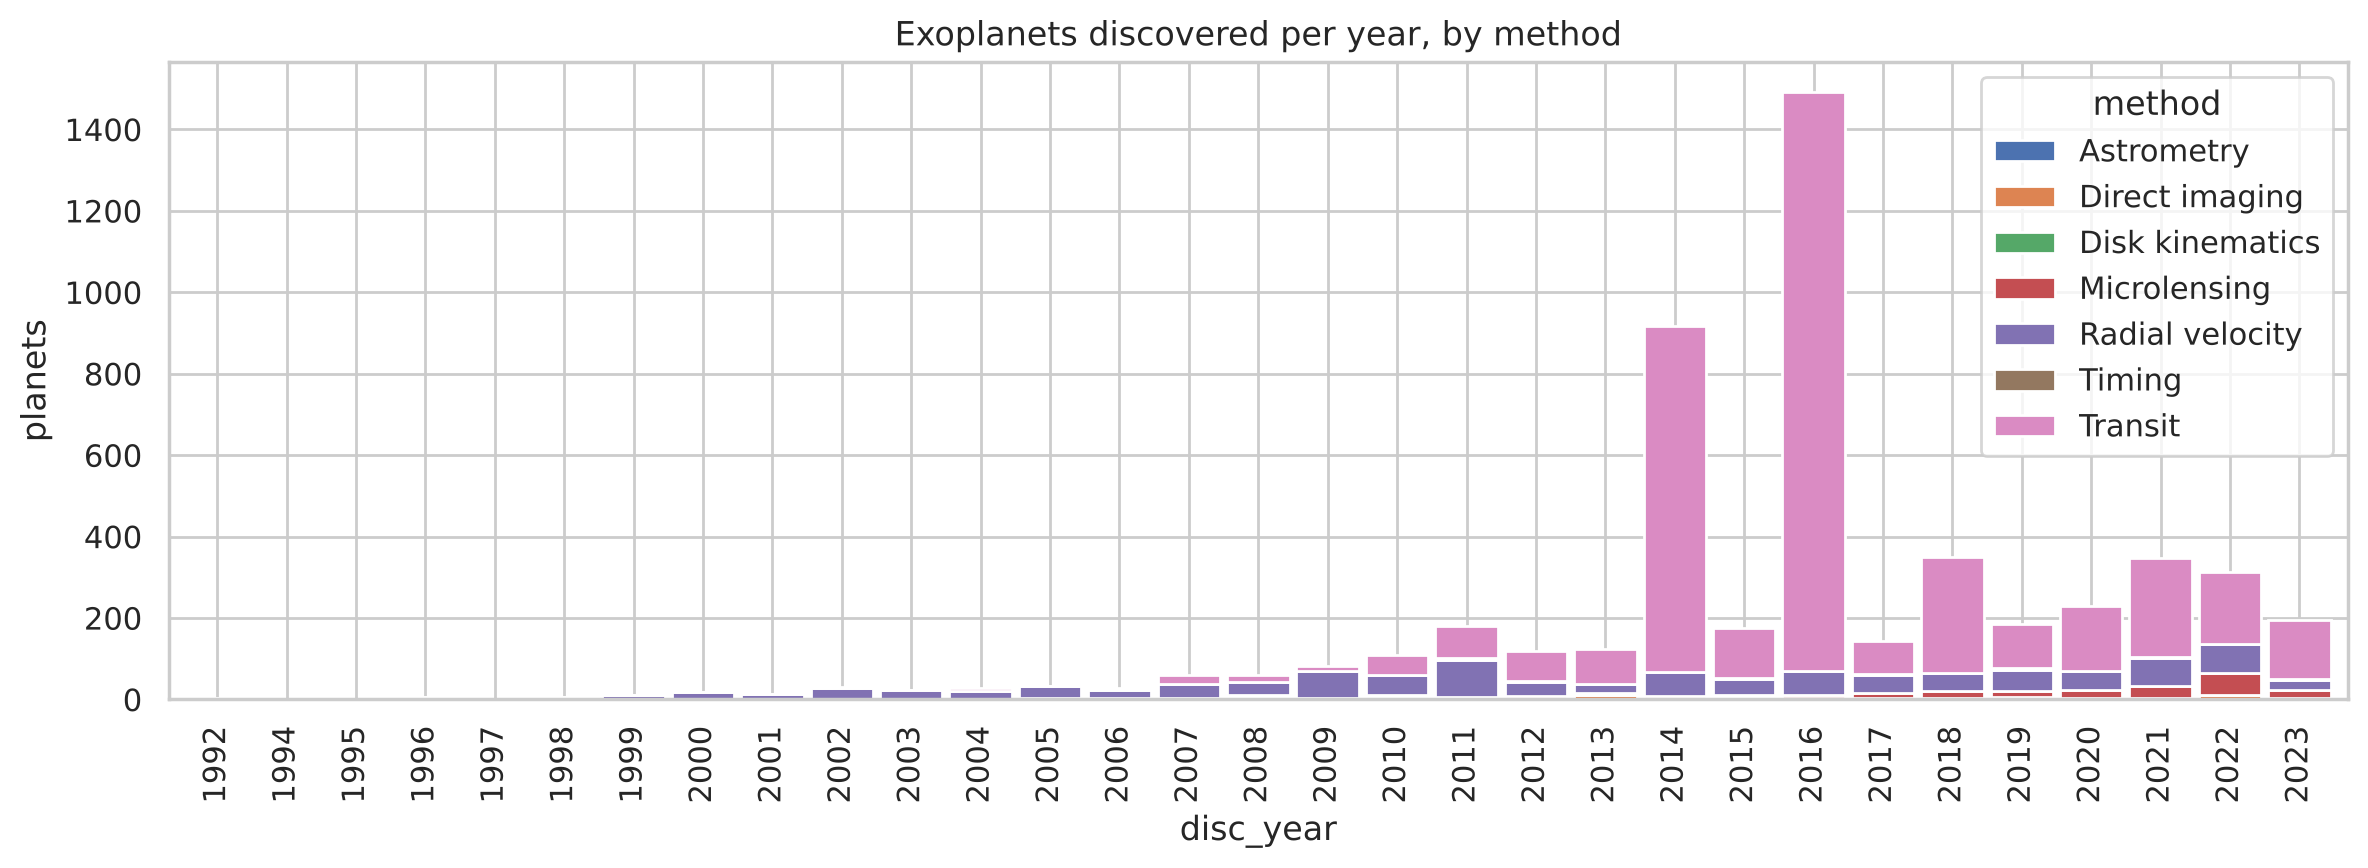

- INSIGHT 1: 5,288 confirmed planets; the record year was 2016 with 1491 discoveries. 75% were found by the Transit method.


In [14]:
disc = oec.groupby(["disc_year", "method"]).size().unstack(fill_value=0)
disc.plot(kind="bar", stacked=True, figsize=(12, 4.5), width=0.9)
plt.title("Exoplanets discovered per year, by method"); plt.ylabel("planets")
plt.xticks(rotation=90); savefig("02_discoveries.png")
peak = oec["disc_year"].value_counts().idxmax()
log(f"- INSIGHT 1: {len(oec):,} confirmed planets; the record year was {peak} with "
    f"{oec['disc_year'].value_counts().max()} discoveries. "
    f"{oec['method'].value_counts(normalize=True).iloc[0]:.0%} were found by the {oec['method'].value_counts().index[0]} method.")

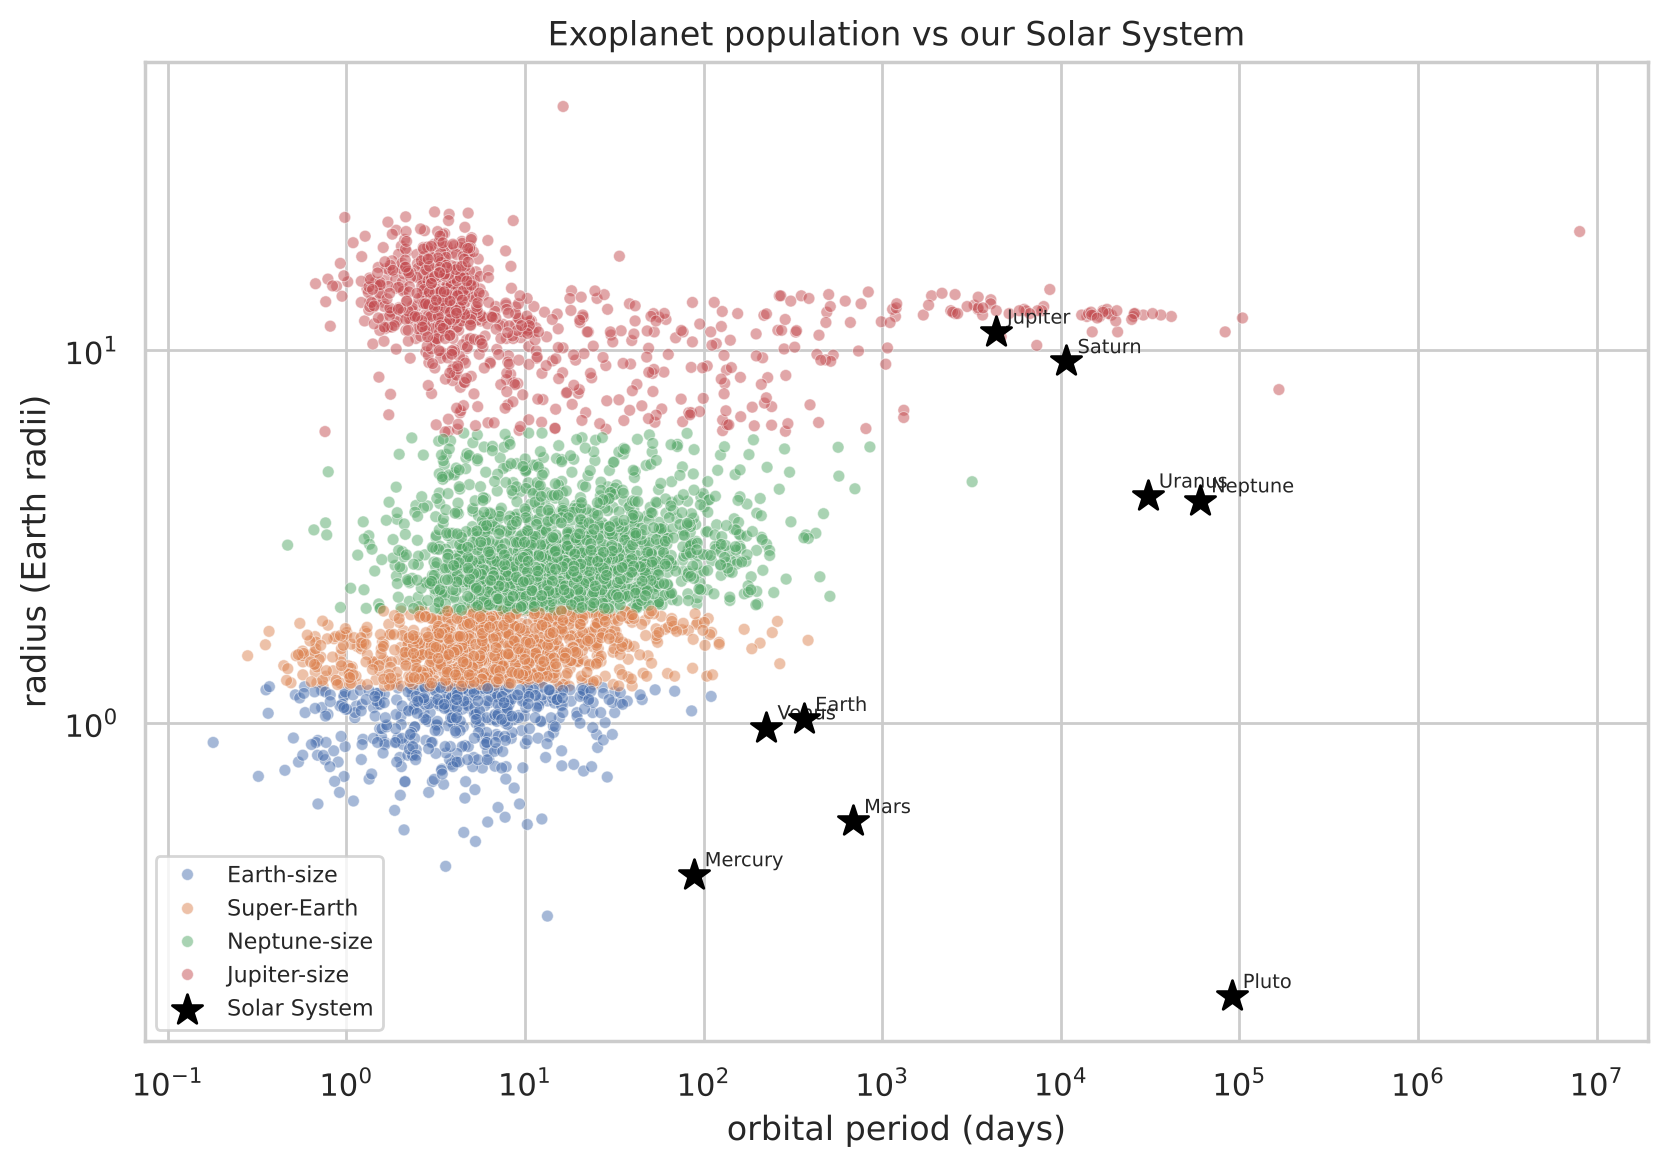

- INSIGHT 2: 44% of planets orbit their star in under 10 days. Most are 'hot' worlds because short orbits are the easiest to detect (selection bias), not because they are most common.
- INSIGHT 3: size classes: Neptune-size=1913, Jupiter-size=1669, Super-Earth=1213, Earth-size=478


In [15]:
plt.figure(figsize=(8.5, 6))
sns.scatterplot(data=oec, x="period_days", y="radius_earth", hue="size_class", alpha=0.5, s=18)
sol = solar.assign(radius_earth=solar["radius"] * RJUP_TO_REARTH)
plt.scatter(sol["period"], sol["radius_earth"], c="black", marker="*", s=130, label="Solar System", zorder=5)
for r in sol.itertuples():
    plt.annotate(r.name, (r.period, r.radius_earth), fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("orbital period (days)"); plt.ylabel("radius (Earth radii)")
plt.title("Exoplanet population vs our Solar System"); plt.legend(fontsize=8)
savefig("03_radius_period.png")
close_in = (oec["period_days"] < 10).mean()
log(f"- INSIGHT 2: {close_in:.0%} of planets orbit their star in under 10 days. Most are 'hot' worlds "
    "because short orbits are the easiest to detect (selection bias), not because they are most common.")
log("- INSIGHT 3: size classes: " + ", ".join(f"{k}={v}" for k, v in oec["size_class"].value_counts().items()))

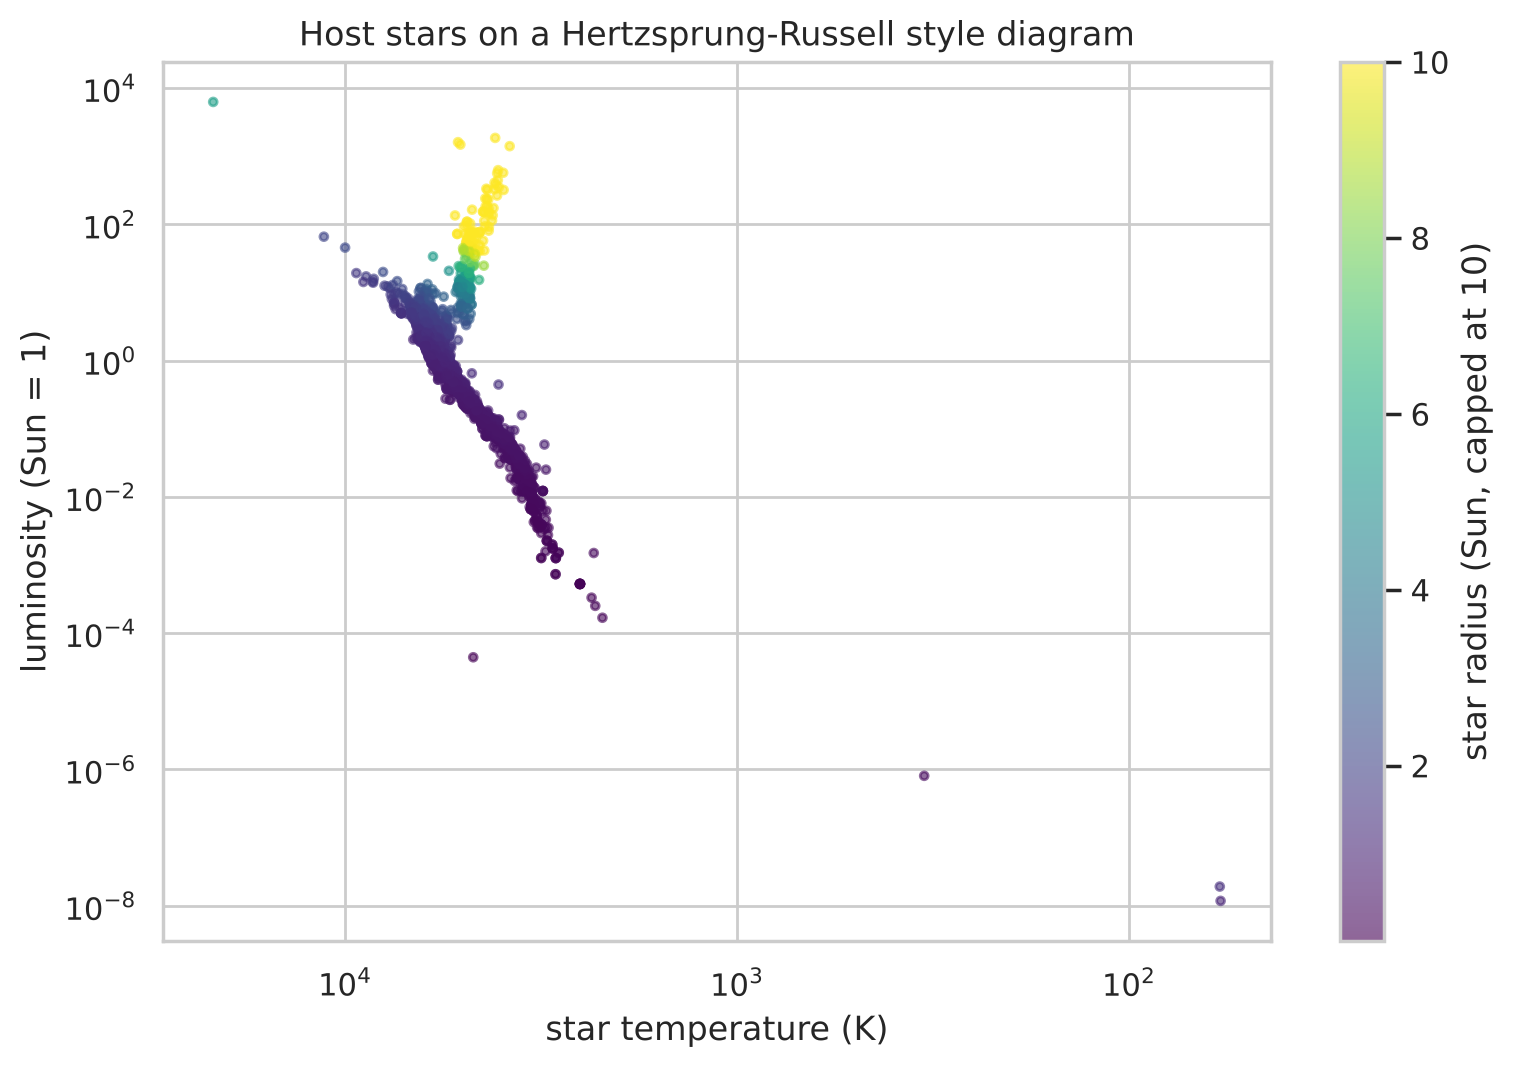

- INSIGHT 4: host star classes: G=2207, K=1332, F=896, M=267, A=15, B=5


In [16]:
plt.figure(figsize=(8, 5.5))
hz = oec.dropna(subset=["star_lum_lsun", "star_temp_k"])
sc = plt.scatter(hz["star_temp_k"], hz["star_lum_lsun"], c=hz["star_radius_rsun"].clip(upper=10), s=8, cmap="viridis", alpha=0.6)
plt.xscale("log"); plt.yscale("log"); plt.gca().invert_xaxis()
plt.xlabel("star temperature (K)"); plt.ylabel("luminosity (Sun = 1)"); plt.colorbar(sc, label="star radius (Sun, capped at 10)")
plt.title("Host stars on a Hertzsprung-Russell style diagram")
savefig("04_hr_diagram.png")
log(f"- INSIGHT 4: host star classes: " + ", ".join(f"{k}={v}" for k, v in oec["star_class"].value_counts().items() if v > 0))

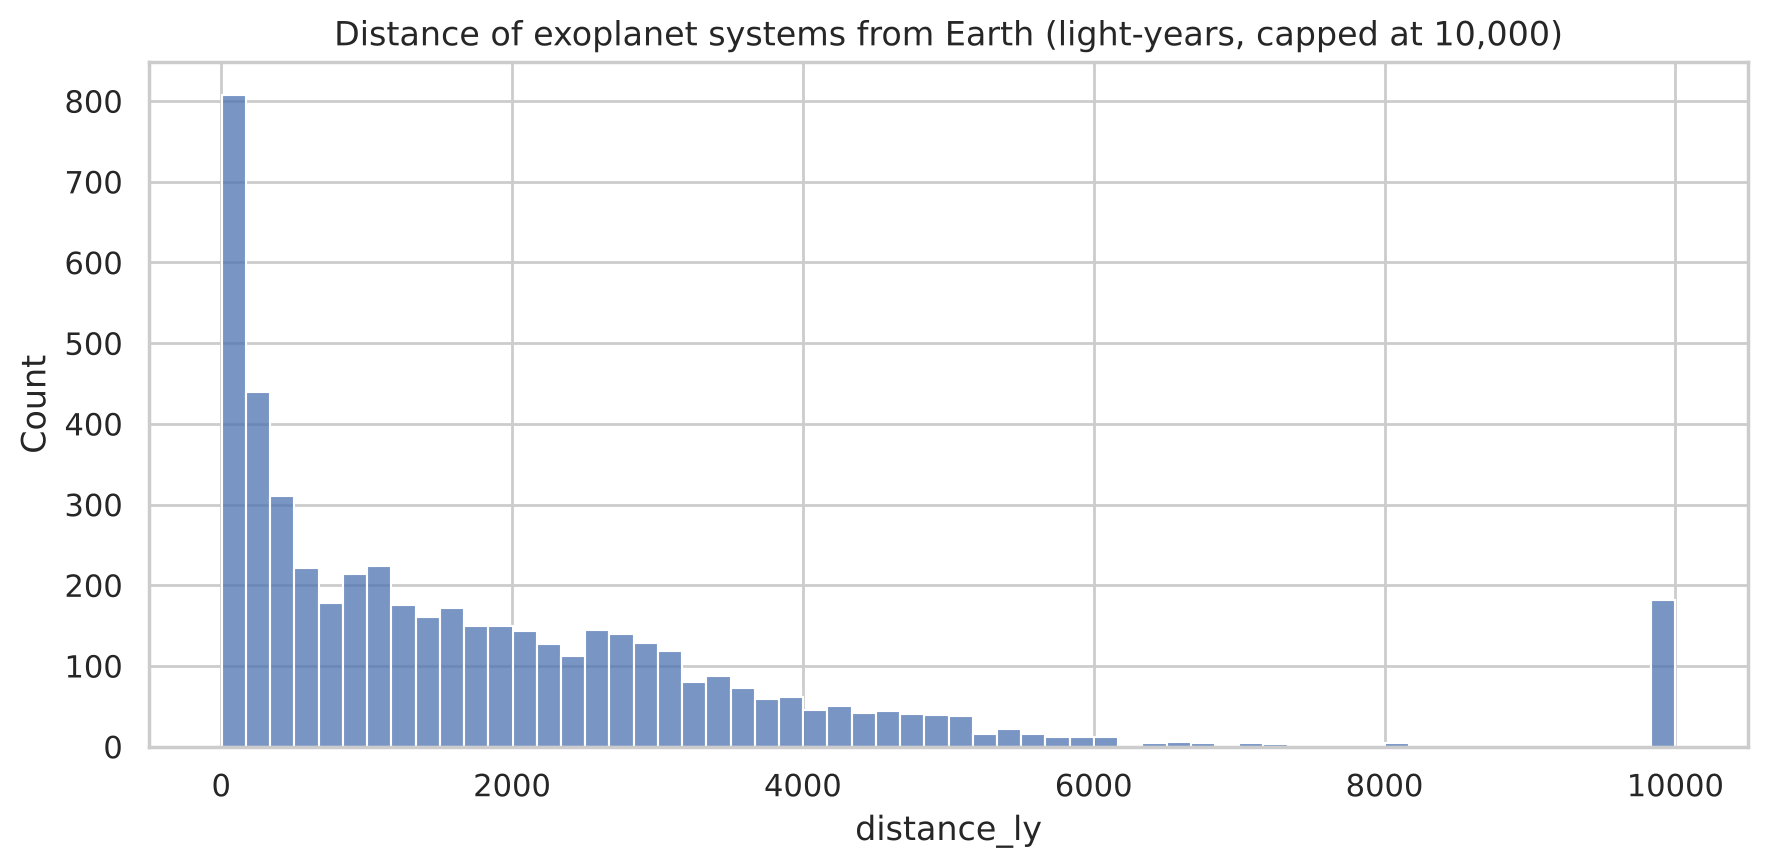

- INSIGHT 5: median distance 1,305 light-years; closest system Proxima Centauri at 4.2 ly.


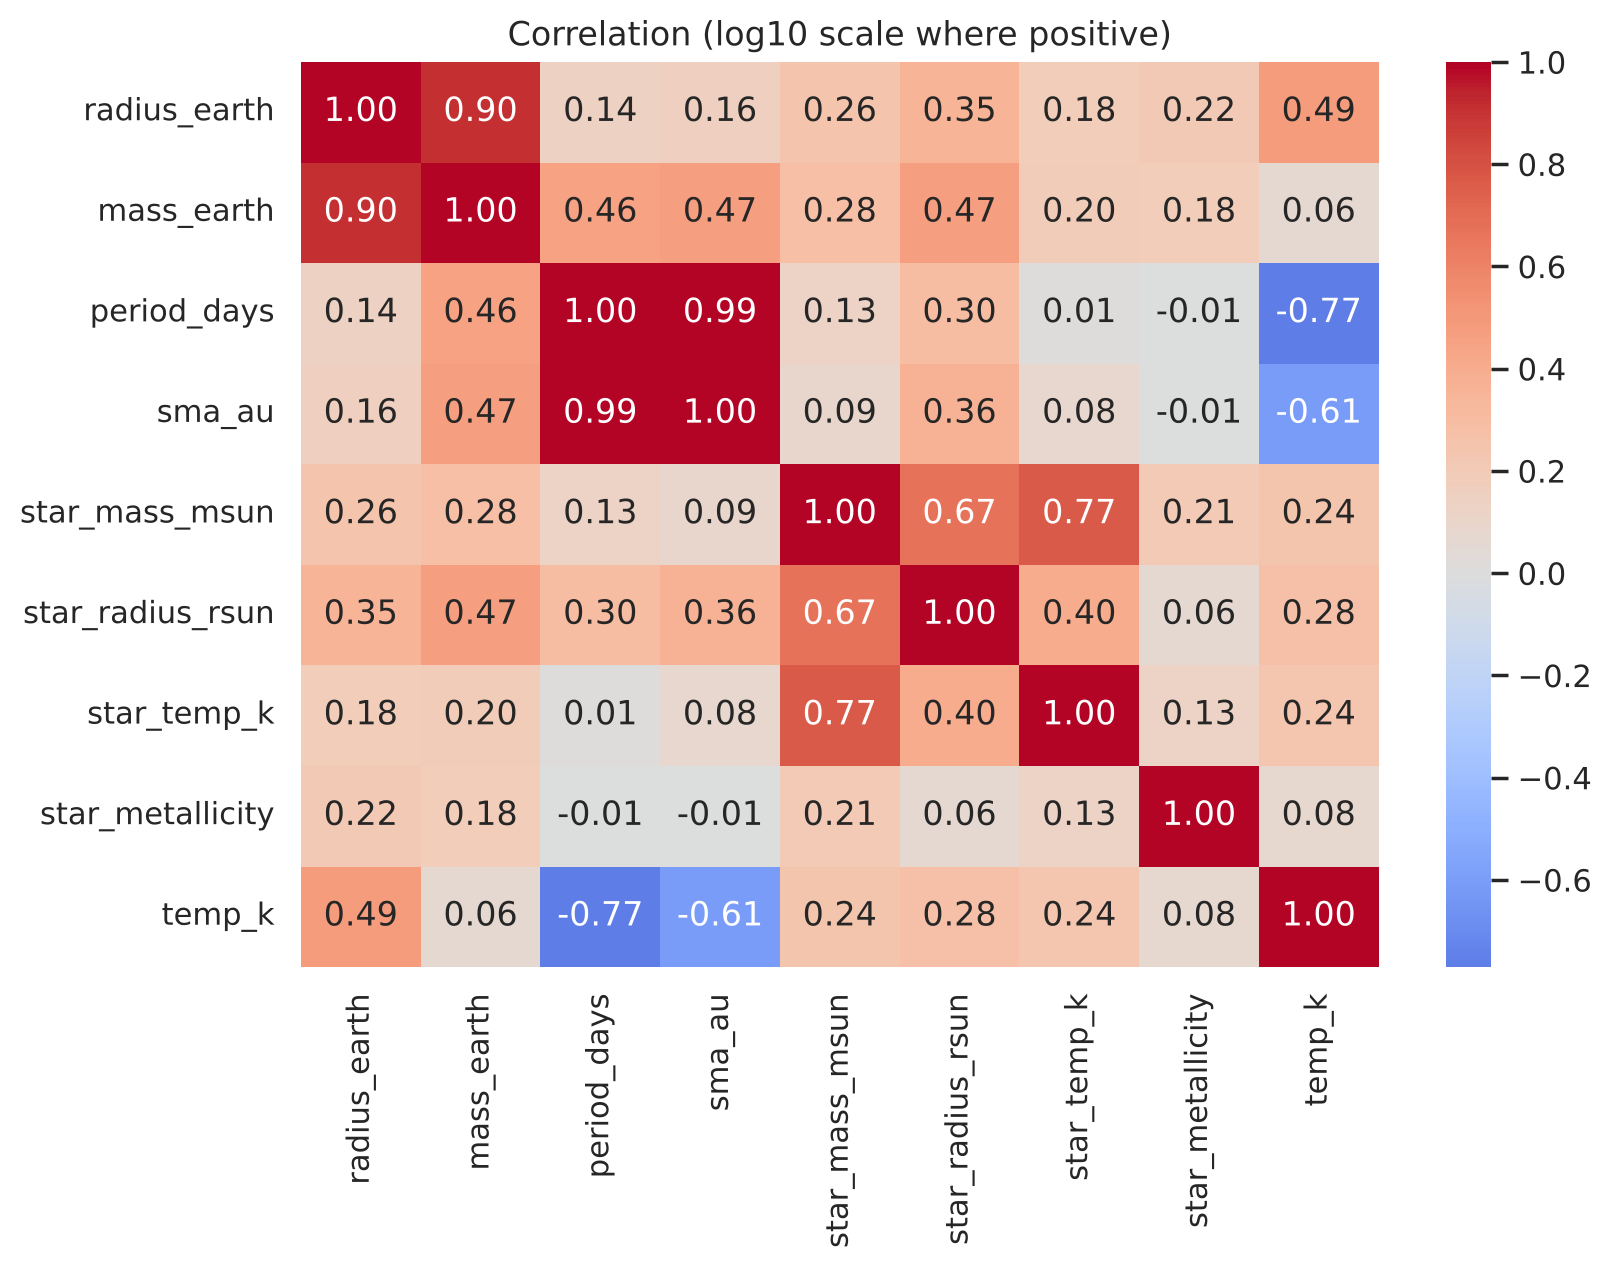

In [17]:
plt.figure(figsize=(9, 4.5))
sns.histplot(oec["distance_ly"].dropna().clip(upper=10000), bins=60)
plt.title("Distance of exoplanet systems from Earth (light-years, capped at 10,000)")
savefig("05_distance.png")
log(f"- INSIGHT 5: median distance {oec['distance_ly'].median():,.0f} light-years; closest system "
    f"{oec.loc[oec['distance_ly'].idxmin(), 'host']} at {oec['distance_ly'].min():.1f} ly.")

num = ["radius_earth", "mass_earth", "period_days", "sma_au", "star_mass_msun", "star_radius_rsun", "star_temp_k",
       "star_metallicity", "temp_k"]
cm = np.log10(oec[num].where(oec[num] > 0)).join(oec[["star_metallicity"]].rename(columns={"star_metallicity": "met"}))
cm["star_metallicity"] = oec["star_metallicity"]
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(cm[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (log10 scale where positive)"); savefig("06_correlation.png")

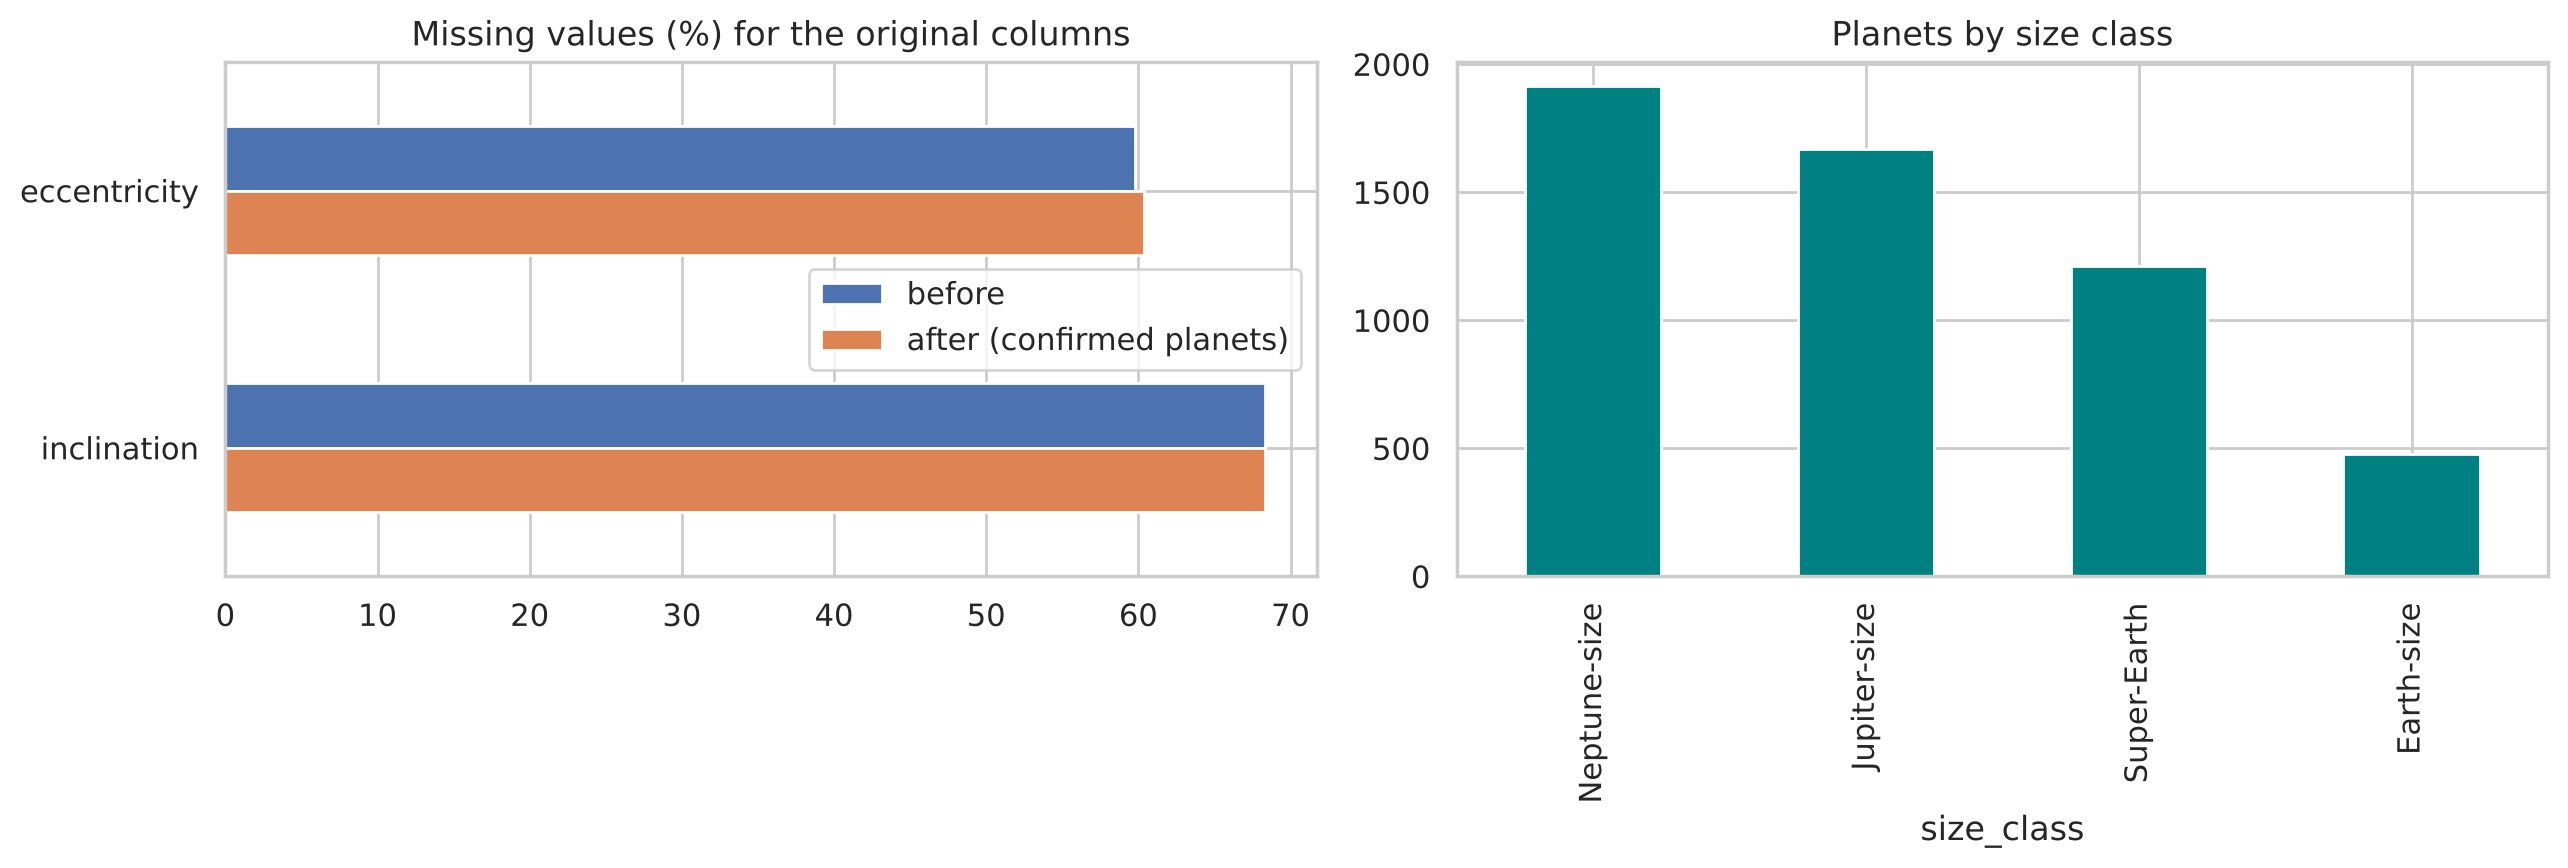

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
before = pd.Series(WLOG["missing_before"]).sort_values(ascending=False).head(12)
after = (oec.isna().mean() * 100).round(1)[before.index.intersection(oec.columns)]
pd.DataFrame({"before": before, "after (confirmed planets)": after}).dropna().plot.barh(ax=ax[0])
ax[0].set_title("Missing values (%) for the original columns"); ax[0].invert_yaxis()
oec["size_class"].value_counts().plot.bar(ax=ax[1], color="teal"); ax[1].set_title("Planets by size class")
savefig("07_missing_and_classes.png")
WLOG["missing_after"] = (oec.isna().mean() * 100).round(1).to_dict()

## 7. Preprocessing for Modelling
**Goal:** predict `log_radius_earth` from orbit and star properties.
**Leakage control:** planets of the same star are similar, so a random split would leak. We use a
**grouped split by host star** (no star appears in both train and test). Imputer, scaler and encoder
are fitted on the training set only.

In [19]:
num_f = ["log_period", "star_mass_msun", "star_radius_rsun", "star_temp_k", "star_metallicity"]
cat_f = ["method"]
md = oec.dropna(subset=["log_radius_earth", "log_period"]).copy()
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(md, groups=md["host"]))
Xtr, ytr, Xte, yte = md.iloc[tr][num_f + cat_f], md.iloc[tr]["log_radius_earth"], md.iloc[te][num_f + cat_f], md.iloc[te]["log_radius_earth"]
log(f"- Grouped split by host star: train {len(Xtr):,} / test {len(Xte):,} planets "
    f"(shared hosts: {len(set(md.iloc[tr]['host']) & set(md.iloc[te]['host']))})")

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_f),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_f)])

- Grouped split by host star: train 3,250 / test 792 planets (shared hosts: 0)


In [20]:
Xt = prep.fit_transform(Xtr)
q = pd.DataFrame({"stage": ["raw catalogue", "cleaned + integrated", "model-ready (train)"],
                  "rows": [len(oec_raw), len(oec), Xt.shape[0]],
                  "columns": [oec_raw.shape[1], oec.shape[1], Xt.shape[1]],
                  "missing_cells": [int(oec_raw.isna().sum().sum()), int(oec.isna().sum().sum()), int(np.isnan(Xt).sum())]})
q["missing_%"] = (q["missing_cells"] / (q["rows"] * q["columns"]) * 100).round(1)  # share is fairer: derived columns add cells
log("\nData quality before vs after:\n\n" + q.to_markdown(index=False))

res = []
for n, est in [("Linear Regression", LinearRegression()),
               ("Random Forest", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))]:
    p = Pipeline([("prep", prep), ("model", est)]).fit(Xtr, ytr)
    pr = p.predict(Xte)
    res.append({"model": n, "R2": r2_score(yte, pr), "RMSE (log10 R_earth)": np.sqrt(mean_squared_error(yte, pr))})
res = pd.DataFrame(res).round(3)
log("\nRadius prediction on unseen host stars:\n\n" + res.to_markdown(index=False))
res


Data quality before vs after:

| stage                |   rows |   columns |   missing_cells |   missing_% |
|:---------------------|-------:|----------:|----------------:|------------:|
| raw catalogue        |   5414 |        25 |           46236 |        34.2 |
| cleaned + integrated |   5288 |        49 |           68997 |        26.6 |
| model-ready (train)  |   3250 |         9 |               0 |         0   |



Radius prediction on unseen host stars:

| model             |    R2 |   RMSE (log10 R_earth) |
|:------------------|------:|-----------------------:|
| Linear Regression | 0.216 |                  0.33  |
| Random Forest     | 0.383 |                  0.292 |


,model,R2,RMSE (log10 R_earth)
0,Linear Regression,0.216,0.330
1,Random Forest,0.383,0.292


In [21]:
# Save outputs for the dashboard
final_cols = [c for c in oec.columns if c not in ("size_class_source",)] + ["size_class_source"]
oec[final_cols].to_csv(PROC / "exoplanets_clean.csv", index=False)
solar_out = solar.assign(radius_earth=solar["radius"] * RJUP_TO_REARTH, mass_earth=solar["mass"] * MJUP_TO_MEARTH)[
    ["name", "radius_earth", "mass_earth", "period", "semimajoraxis"]].rename(
    columns={"period": "period_days", "semimajoraxis": "sma_au"})
solar_out.to_csv(PROC / "solar_system.csv", index=False)
WLOG.update(clean_rows=int(len(oec)), clean_cols=int(oec.shape[1]), steps=[l for l in REPORT if l.startswith("-")])
(PROC / "wrangling_log.json").write_text(json.dumps(WLOG, indent=1, default=str))
(BASE / "outputs").mkdir(exist_ok=True)
(BASE / "outputs" / "report.md").write_text("# Auto-generated results report\n\n" + "\n".join(REPORT), encoding="utf-8")
print("\nSaved processed data for the dashboard. Run:  streamlit run app.py")


Saved processed data for the dashboard. Run:  streamlit run app.py
